# 01. Limpeza e Preparação de Dados — Layoffs no Entretenimento Digital (2020–2026)

**Descrição:** Auditoria de qualidade, filtragem do recorte setorial (`Consumer` e `Media`), tratamento de inconsistências geográficas e duplicidades parciais, padronização de tipos e engenharia de atributos temporais e corporativos a partir da base bruta do *Layoffs.fyi*, preparando o dataset para carga no PostgreSQL e análise estatística.

## Índice
<div style="line-height:1.5">

<span style="font-size:20px">**1.** Importação e Auditoria Inicial da Base Bruta</span><br>
<span style="font-size:20px">**2.** Classificação de Escopo Setorial</span><br>
<span style="font-size:20px">**3.** Auditoria de Duplicidades e Valores Ausentes</span><br>
   <span style="font-size:18px">&emsp;**3.1.** Explorando Duplicidade</span><br>
   <span style="font-size:18px">&emsp;**3.2.** Tratando Duplicidade</span><br>
   <span style="font-size:18px">&emsp;**3.3.** Explorando Valores Ausentes</span><br>
   <span style="font-size:18px">&emsp;**3.4.** Tratamento Inicial de Valores Ausentes</span><br>
   <span style="font-size:18px">&emsp;**3.5.** Exploração de Valores Ausentes Pontuais</span><br>
   <span style="font-size:18px">&emsp;**3.6.** Tratando de Valores Ausentes Pontuais</span><br>
<span style="font-size:20px">**4.** Padranização Geográfica e Categórica</span><br>
   <span style="font-size:18px">&emsp;**4.1.** Auditoria Geográfica e Categórica</span><br>
   <span style="font-size:18px">&emsp;**4.2.** Tratamento Geográfica e Categórica</span><br>
<span style="font-size:20px">**5.** Conversão de Tipos e Engenharia Temporal</span><br>
<span style="font-size:20px">**6.** Análise e Tratamento de Outliers </span><br>
<span style="font-size:20px">**7.** Validação Final e Exportação</span><br>

</div>

---

## 1. Importação e Auditoria Inicial da Base Bruta

In [53]:
# Configuração do Jupyter (Autoreload)
%load_ext autoreload
%autoreload 2

# Imports
import os
import sys
import unicodedata
import numpy as np
import pandas as pd
import seaborn as sns
from pathlib import Path
import matplotlib.pyplot as plt

# Adiciona a raiz do projeto ao sys.path para conseguir importar a pasta src
sys.path.append(os.path.abspath('..'))

# Módulos auxiliares
from src.io.data_load import load_csv
from src.plots.visualizations import (
    chart_data_quality, 
    chart_partial_duplicates, 
    chart_completeness_profile
)
from src.utils.data_quality import (
    check_data_quality, 
    inspect_partial_duplicates, 
    cross_tabulation_sector_company
)

# Configurações de exibição do Pandas e estética dos gráficos
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 100)
pd.set_option('display.float_format', '{:.2f}'.format)

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['figure.dpi'] = 150

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
df_raw = load_csv("layoffs.csv")

In [3]:
df = df_raw.copy()

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4675 entries, 0 to 4674
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   company              4675 non-null   str    
 1   location             4674 non-null   str    
 2   total_laid_off       3048 non-null   float64
 3   date                 4675 non-null   str    
 4   percentage_laid_off  2917 non-null   float64
 5   industry             4673 non-null   str    
 6   source               4672 non-null   str    
 7   stage                4667 non-null   str    
 8   funds_raised         4119 non-null   float64
 9   country              4673 non-null   str    
 10  date_added           4675 non-null   str    
dtypes: float64(3), str(8)
memory usage: 401.9 KB


In [5]:
df_raw.head(10)

,company,location,total_laid_off,date,percentage_laid_off,industry,source,stage,funds_raised,country,date_added
0,Qualcomm,"Bengaluru, Non-U.S.",1500.00,11/11/2026,NaN,Hardware,https://timesofindia.indiatimes.com/business/india-business/qualcomm-layoffs-1500-employees-in-i...,Post-IPO,NaN,India,11/14/2026
1,Innoviz,"Tel Aviv, Non-U.S.",80.00,11/11/2026,0.20,Transportation,https://www.calcalistech.com/ctechnews/article/j23ch7kvd,Post-IPO,547.00,Israel,11/14/2026
2,Polymarket,New York City,NaN,11/11/2026,NaN,Finance,https://www.reuters.com/business/polymarket-cuts-jobs-contracts-prediction-market-competition-he...,Series E,2300.00,United States,11/14/2026
3,Val Town,New York City,NaN,11/10/2026,1.00,Product,https://blog.val.town/winding-down,Seed,7.00,United States,11/14/2026
4,Coursera,SF Bay Area,NaN,11/9/2026,0.10,Education,https://ca.investing.com/news/stock-market-news/faa-orders-nationwide-ground-stop-citing-extraor...,Acquired,458.00,United States,11/14/2026
5,Abridge,SF Bay Area,NaN,11/6/2026,NaN,Healthcare,https://www.modernhealthcare.com/health-tech/mh-abridge-layoffs-realignment-ai/,Series E,757.00,United States,11/7/2026
6,ServiceNow,SF Bay Area,NaN,11/6/2026,NaN,Support,https://www.calcalistech.com/ctechnews/article/s1t03axtg,Post-IPO,84.00,United States,11/10/2026
7,Bria,"Tel Aviv, Non-U.S.",20.00,11/5/2026,0.33,AI,https://www.calcalistech.com/ctechnews/article/5nu7gxmim,Series B,66.00,Israel,11/7/2026
8,Heidi Health,"Melbourne, Non-U.S.",108.00,11/4/2026,0.18,Healthcare,https://www.smh.com.au/technology/ai-start-up-heidi-cuts-jobs-weeks-after-raising-475-million-20...,Series C,432.00,Australia,11/7/2026
9,Block,SF Bay Area,NaN,11/4/2026,NaN,Finance,https://www.businessinsider.com/jack-dorsey-block-layoffs-second-round-job-cuts-cash-app-2026-11,Post-IPO,150.00,United States,11/7/2026


In [6]:
df.describe()

,total_laid_off,percentage_laid_off,funds_raised
count,3048.00,2917.00,4119.00
mean,310.84,0.30,968.05
std,1107.05,0.31,5574.12
min,3.00,0.00,0.70
25%,40.00,0.10,56.00
50%,90.00,0.17,177.00
75%,200.00,0.33,489.00
max,22000.00,1.00,121900.00


In [7]:
for col in df.columns:
    print(f"\nColuna: {col}")
    print(df[col].value_counts(dropna=False).head(10))


Coluna: company
company
Amazon        26
Google        19
Microsoft     18
Salesforce    15
Intel         13
Oracle        12
Rivian        12
Meta          12
Expedia       11
TikTok        10
Name: count, dtype: int64

Coluna: location
location
SF Bay Area            1160
New York City           460
Seattle                 207
Bengaluru, Non-U.S.     201
Boston                  197
Tel Aviv, Non-U.S.      179
Los Angeles             172
London, Non-U.S.        143
Berlin, Non-U.S.        100
Toronto, Non-U.S.        83
Name: count, dtype: int64

Coluna: total_laid_off
total_laid_off
NaN       1627
100.00     191
30.00      117
200.00     116
40.00      108
50.00       98
60.00       86
80.00       79
150.00      77
20.00       72
Name: count, dtype: int64

Coluna: date
date
4/2/2020      27
4/3/2020      25
1/18/2023     24
3/27/2020     23
4/8/2020      21
4/1/2020      21
11/15/2022    20
2/1/2023      19
1/10/2023     19
1/19/2023     18
Name: count, dtype: int64

Coluna: percent

### Resumo da Auditoria Inicial (Base Bruta)

* **Dimensões:** `4.675` registros e `11` colunas.
* **Estrutura e Tipagem:**
  * **Texto (`str` / 8 colunas):** `company`, `date` e `date_added` (4.675 válidos | 0 nulos), `location` (4.674 válidos | 1 nulo), `industry` e `country` (4.673 válidos | 2 nulos cada), `source` (4.672 válidos | 3 nulos) e `stage` (4.667 válidos | 8 nulos). *(Datas ainda como string, exigindo conversão para `datetime`.)*
  * **Numéricas (`float64` / 3 colunas):** `total_laid_off` (3.048 válidos | 1.627 nulos), `percentage_laid_off` (2.917 válidos | 1.758 nulos) e `funds_raised` (4.119 válidos | 556 nulos).
* **Diagnóstico Preliminar:**
  * Colunas críticas de identificação (`company`, `date`, `date_added`) possuem 100% de preenchimento, e os 2 nulos de `industry` serão auditados antes do filtro setorial.
  * Forte assimetria à direita nas variáveis quantitativas: em `total_laid_off`, a média (`310,84`) é mais de 3x superior à mediana (`90,00`), com amplitude de `3` a `22.000` demitidos.
  
<br>

---

## 2. Classificação de Escopo Setorial

In [8]:
# Distribuição de setores na base bruta (incluindo nulos)
print("Distribuição de setores (Top 10 + Nulos):")
print(df['industry'].value_counts(dropna=False).head(20))

Distribuição de setores (Top 10 + Nulos):
industry
Finance           554
Retail            369
Healthcare        339
Consumer          322
Other             320
Transportation    278
Food              261
Marketing         226
Crypto            184
Security          171
Education         168
Real Estate       167
Media             165
Data              148
HR                117
Travel            115
Hardware           92
Infrastructure     80
Sales              80
Logistics          76
Name: count, dtype: int64


In [9]:
# Auditoria dos 2 registros com 'industry' nulo
print("\nRegistros com 'industry' nulo:")
display(df[df['industry'].isnull()][['company', 'location', 'total_laid_off', 'date', 'source']])


Registros com 'industry' nulo:


,company,location,total_laid_off,date,source
536,Eyeo,"Cologne, Non-U.S.",NaN,7/28/2025,https://www.adexchanger.com/privacy/eyeo-names-new-ceo-cuts-40-of-staff-and-refocuses-the-busine...
1604,Appsmith,SF Bay Area,35.00,9/22/2023,https://inc42.com/buzz/exclusive-insight-partners-backed-appsmith-lays-off-25-of-its-workforce/


In [10]:
# Remover apenas os 2 registros sem classificação setorial ('industry' nulo)
df_clean = df.dropna(subset=['industry']).copy().reset_index(drop=True)

In [11]:
# Criar flag de escopo setorial para permitir análise interna + benchmark de mercado
entertainment_sectors = ['Consumer', 'Media']
df_clean['sector_scope'] = np.where(
    df_clean['industry'].isin(entertainment_sectors),
    'Digital Entertainment',
    'Other Industries'
)


print(f"\nDimensões após filtro: {df_clean.shape[0]} linhas e {df_clean.shape[1]} colunas")
print(f"Representatividade na base bruta: {(len(df_clean) / len(df) * 100):.2f}%")
print("\nContagem por setor no recorte:")
print(df_clean['sector_scope'].value_counts())


Dimensões após filtro: 4673 linhas e 12 colunas
Representatividade na base bruta: 99.96%

Contagem por setor no recorte:
sector_scope
Other Industries         4186
Digital Entertainment     487
Name: count, dtype: int64


### Resumo da Classificação Setorial

* **Auditoria de Nulos em `industry`:** Os `2` registros sem classificação setorial na base bruta (*Eyeo* e *Appsmith*) foram auditados e removidos, mantendo **99,96%** da base original (`4.673` registros e `12` colunas, após a criação da coluna `sector_scope`).
* **Segmentação (`sector_scope`):**
  * **`Digital Entertainment` (`Consumer` + `Media`):** `487` eventos (**10,42%** da base válida), divididos em `322` em `Consumer` e `165` em `Media`.
  * **`Other Industries` (Demais setores de tecnologia):** `4.186` eventos (**89,58%** da base válida), mantidos como grupo de *benchmark* de mercado.

<br>

---

## 3. Auditoria de Duplicidades e Valores Ausentes

In [12]:
# Checar Colunas do DataFrame Limpo
pd.DataFrame({'colunas': df_clean.columns})

,colunas
0,company
1,location
2,total_laid_off
3,date
4,percentage_laid_off
5,industry
6,source
7,stage
8,funds_raised
9,country


In [13]:
# Gerar relatório de qualidade dos dados
qa_report = check_data_quality(df_clean)
display(qa_report)

,Quantidade,Incidência (%)
percentage_laid_off (Nulos/NaN),1758,37.62
total_laid_off (Nulos/NaN),1626,34.80
funds_raised (Nulos/NaN),555,11.88
Duplicidade Parcial (Mesma Empresa + Data),23,0.49
stage (Nulos/NaN),8,0.17
source (Nulos/NaN),3,0.06
country (Nulos/NaN),2,0.04
location (Nulos/NaN),1,0.02


findfont: Failed to find font weight semibold for Arial, now using 700.
findfont: Failed to find font weight semibold for Arial, now using 700.


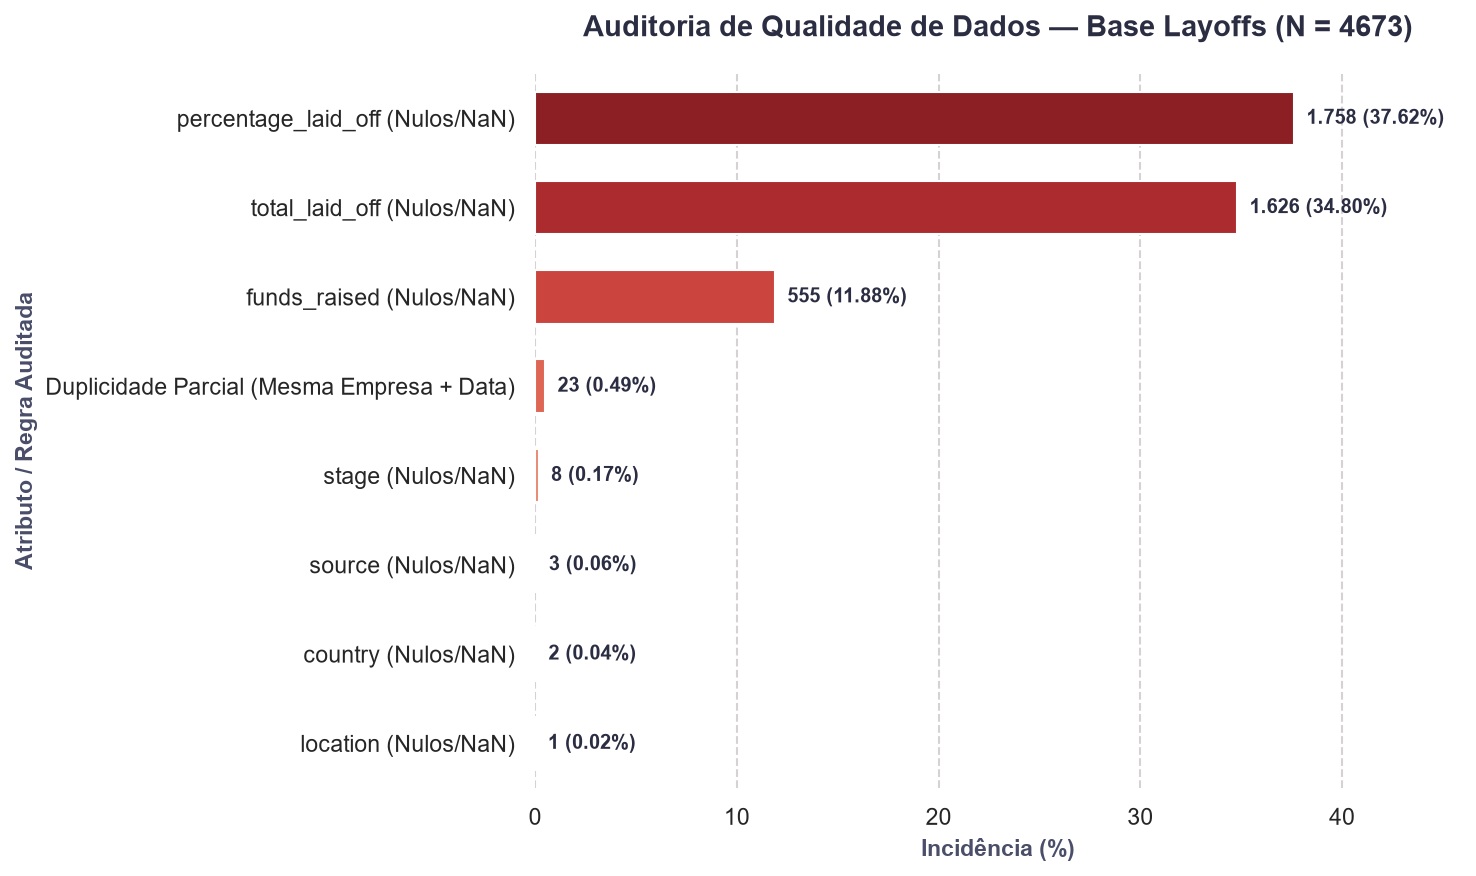

In [14]:
# Visualizar o relatório de qualidade dos dados
chart_data_quality(
    qa_report, 
    name_df=f"Base Layoffs (N = {len(df_clean)})", 
    save_path="../docs/figures/cleaning/data_quality_report.png"
)

### 3.1 Explorando Duplicidade

In [15]:
# Inspecionar as 23 duplicidades parciais (mesma empresa + mesma data)
dup_mask = df_clean.duplicated(subset=['company', 'date'], keep=False)
print(f"Total de linhas envolvidas em duplicidade parcial: {dup_mask.sum()}")
display(
    df_clean[dup_mask]
    .sort_values(['company', 'date'])
    [['company', 'location', 'total_laid_off', 'percentage_laid_off', 'date', 'industry', 'source']]
)

Total de linhas envolvidas em duplicidade parcial: 44


,company,location,total_laid_off,percentage_laid_off,date,industry,source
144,Amazon,Port St. Lucie,1110.00,NaN,7/22/2026,Retail,https://www.msn.com/en-us/money/companies/amazon-to-renovate-two-florida-warehouses-for-400m-cut...
146,Amazon,Seattle,NaN,NaN,7/22/2026,Retail,https://www.reuters.com/business/world-at-work/amazon-cuts-jobs-its-artificial-general-intellige...
3627,Anodot,"Tel Aviv, Non-U.S.",35.00,0.27,7/6/2022,Data,https://www.calcalistech.com/ctechnews/article/sypfe11ms5
3629,Anodot,"Tel Aviv, Non-U.S.",15.00,0.20,7/6/2022,Data,https://www.calcalistech.com/ctechnews/article/sjy5hbre3
3194,Beyond Meat,Los Angeles,200.00,0.19,10/14/2022,Food,https://www.cnbc.com/2022/10/14/beyond-meat-to-cut-19percent-of-its-workforce-as-sales-stock-str...
3195,Beyond Meat,Los Angeles,200.00,0.19,10/14/2022,Food,https://www.fooddive.com/news/beyond-meat-layoffs-cut-revenue-outlook/634141/
4490,Bustle Digital Group,New York City,24.00,0.08,4/3/2020,Media,https://digiday.com/media/bustle-digital-group-g-o-media-announce-layoffs-and-cost-saving-measures/
4491,Bustle Digital Group,New York City,19.00,NaN,4/3/2020,Media,https://www.adweek.com/media/bdg-input-mic-layoffs/
3736,Bybit,"Singapore, Non-U.S.",600.00,0.30,6/20/2022,Crypto,https://techcrunch.com/2022/06/20/bybit-crypto-exchange-joins-the-the-list-of-companies-cutting-...
3743,Bybit,"Singapore, Non-U.S.",NaN,NaN,6/20/2022,Crypto,https://twitter.com/WuBlockchain/status/1538807715861962752


In [16]:
summary_dups = inspect_partial_duplicates(df_clean)
display(summary_dups.drop(columns=['diagnostico']))

,company,date,qtd_linhas,cidades,demitidos,percentual,setor,status
0,Beyond Meat,10/14/2022,2,Los Angeles,200,0.1900,Food,🔴 Duplicata exata (Remover)
1,Cazoo,6/7/2022,2,"London, Non-U.S.",750,0.1500,Transportation,🔴 Duplicata exata (Remover)
2,FNZ,7/6/2023,2,"London, Non-U.S.",1000,0.1500,Finance,🔴 Duplicata exata (Remover)
3,Terminus,5/27/2022,2,Atlanta,NaN,NaN,Marketing,🔴 Duplicata exata (Remover)
4,Nomad Health,10/20/2023,2,New York City,119 vs NaN,0.1700 vs 0.2500,Healthcare,🟡 Mesma cidade / dados divergentes
5,StockX,6/28/2022,2,Detroit,120 vs 80,0.0800 vs NaN,Retail,🟡 Mesma cidade / dados divergentes
6,Sendy,8/2/2022,2,"Nairobi, Non-U.S.",54 vs 30,0.2000 vs 0.1000,Logistics,🟡 Mesma cidade / dados divergentes
7,Rapid,4/25/2023,2,SF Bay Area,115 vs 70,0.5000 vs 0.3000,Finance,🟡 Mesma cidade / dados divergentes
8,REE Automotive,2/9/2023,2,"Tel Aviv, Non-U.S.",100 vs 31,0.5000 vs 0.1100,Transportation,🟡 Mesma cidade / dados divergentes
9,Oda,11/1/2022,3,"Oslo, Non-U.S.",70,0.1800 vs 0.0600,Food,🟡 Mesma cidade / dados divergentes


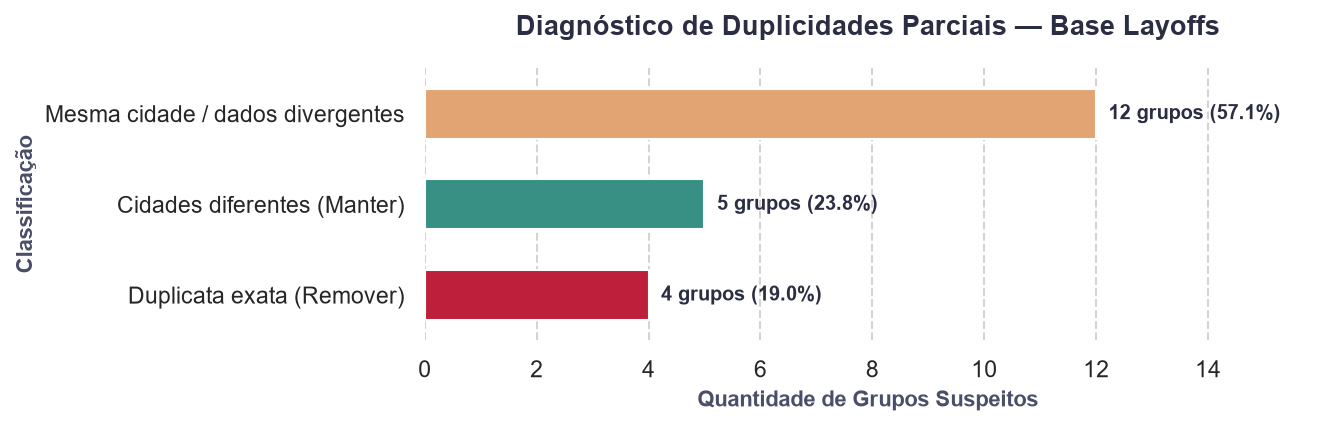

In [17]:
chart_partial_duplicates(
    summary_dups,
    name_df="Base Layoffs",
    save_path="../docs/figures/cleaning/partial_duplicates_summary.png"
)

### 3.2. Tratando Duplicidade


A auditoria realizada na etapa anterior identificou **21 grupos** de registros compartilhando a mesma empresa e data (`company` + `date`), divididos em três cenários:

* **Eventos simultâneos em localidades distintas (5 grupos — Mantidos):** Empresas como *Amazon*, *Samsung*, *Oracle*, *Salesforce* e *Clearco* registraram cortes na mesma data, porém em escritórios ou centros operacionais de cidades diferentes. Por representarem impactos regionais independentes, todos os registros foram preservados.
* **Duplicatas exatas na mesma localidade (4 grupos — Removidos):** Registros idênticos em empresa, data, cidade e métricas (*FNZ*, *Beyond Meat*, *Cazoo* e *Terminus*), originados por múltiplas fontes reportando o mesmo anúncio.
* **Mesma empresa, data e cidade com dados divergentes ou incompletos (12 grupos — Consolidados):** Casos em que houve republicação com valores ausentes (*Bybit*, *Cart.com*, *Xendit*, *Nomad Health*) ou atualizações/recortes parciais da mesma rodada na mesma sede (incluindo *Bustle Digital Group*, único caso no escopo de *Digital Entertainment*).

**Regra de Tratamento Aplicada:**
Para evitar dupla contagem sem descartar cortes multi-cidade legítimos, definiu-se a chave composta **`(company, location, date)`**. Antes da deduplicação, os registros foram ordenados por **completude de atributos** (maior número de colunas preenchidas) e **volume consolidado (`total_laid_off`)**, mantendo-se apenas a primeira ocorrência de cada chave.

In [18]:
# Prioriza registros com menos valores nulos e maior volume consolidado por (company, location, date)
df_clean['_completude'] = df_clean.notna().sum(axis=1)

df_clean = (
    df_clean
    .sort_values(
        by=['company', 'location', 'date', '_completude', 'total_laid_off'],
        ascending=[True, True, True, False, False]
    )
    .drop_duplicates(subset=['company', 'location', 'date'], keep='first')
    .drop(columns=['_completude'])
    .sort_index()
    .reset_index(drop=True)
)

print(f"Total de registros após deduplicação: {len(df_clean):,}".replace(",", "."))

Total de registros após deduplicação: 4.655


In [19]:
summary_dups_treatment = inspect_partial_duplicates(df_clean)
display(summary_dups_treatment.drop(columns=['diagnostico']))

,company,date,qtd_linhas,cidades,demitidos,percentual,setor,status
0,Amazon,7/22/2026,2,Port St. Lucie vs Seattle,1110 vs NaN,NaN,Retail,🟢 Cidades diferentes (Manter)
1,Clearco,6/6/2022,2,"Toronto, Non-U.S. vs Dublin, Non-U.S.",60 vs NaN,NaN,Finance,🟢 Cidades diferentes (Manter)
2,Oracle,8/13/2025,2,SF Bay Area vs Seattle,289 vs 161,NaN,Other,🟢 Cidades diferentes (Manter)
3,Salesforce,9/3/2025,2,"Seattle vs Dublin, Non-U.S.",93 vs 30,NaN,Sales,🟢 Cidades diferentes (Manter)
4,Samsung,7/19/2026,2,New York City vs Dallas,739 vs 100,NaN,Hardware,🟢 Cidades diferentes (Manter)


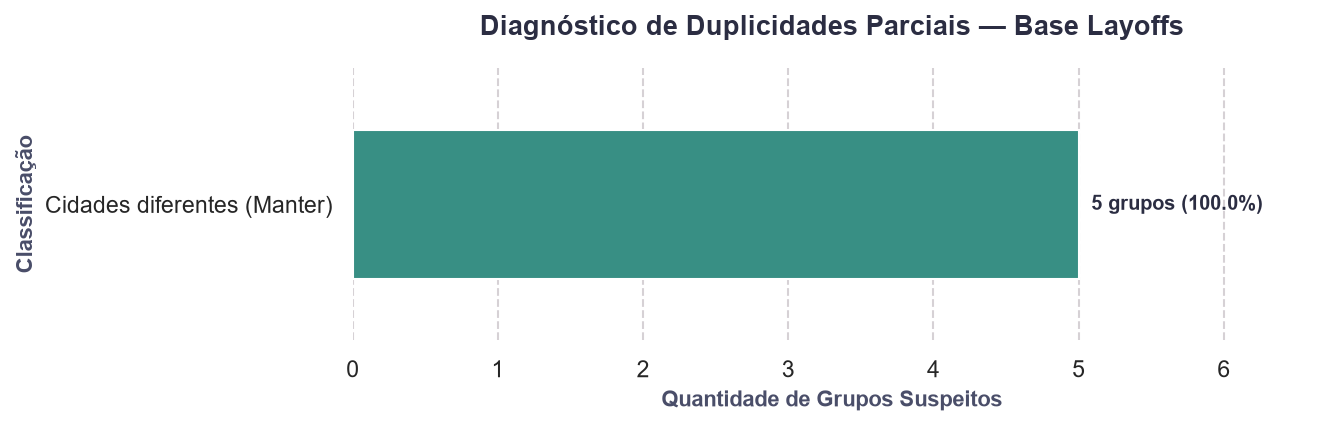

In [20]:
chart_partial_duplicates(summary_dups_treatment, name_df="Base Layoffs")

In [21]:
dup_exatas_pos = df_clean.duplicated().sum()
dup_chave_pos = df_clean.duplicated(subset=['company', 'location', 'date']).sum()

assert dup_exatas_pos == 0, f"Ainda restam {dup_exatas_pos} duplicatas completas!"
assert dup_chave_pos == 0, f"Ainda restam {dup_chave_pos} duplicatas na chave (company, location, date)!"

print(f"Checagem final de duplicidade aprovada: {dup_exatas_pos} completas | {dup_chave_pos} por chave.")

Checagem final de duplicidade aprovada: 0 completas | 0 por chave.


### 3.4. Explorando Valores Ausentes

#### Nulos em `percentage_laid_off`

In [22]:
df_clean['percentage_laid_off'].head(20)

0     NaN
1    0.20
2     NaN
3    1.00
4    0.10
5     NaN
6     NaN
7    0.33
8    0.18
9     NaN
10   0.05
11   1.00
12    NaN
13   0.22
14   0.05
15    NaN
16   0.19
17   0.10
18   0.10
19    NaN
Name: percentage_laid_off, dtype: float64

In [23]:
df_clean['percentage_laid_off'].isnull().value_counts()

percentage_laid_off
False    2904
True     1751
Name: count, dtype: int64

In [24]:
df_clean[df_clean['percentage_laid_off'].isnull()].head(20)

,company,location,total_laid_off,date,percentage_laid_off,industry,source,stage,funds_raised,country,date_added,sector_scope
0,Qualcomm,"Bengaluru, Non-U.S.",1500.00,11/11/2026,NaN,Hardware,https://timesofindia.indiatimes.com/business/india-business/qualcomm-layoffs-1500-employees-in-i...,Post-IPO,NaN,India,11/14/2026,Other Industries
2,Polymarket,New York City,NaN,11/11/2026,NaN,Finance,https://www.reuters.com/business/polymarket-cuts-jobs-contracts-prediction-market-competition-he...,Series E,2300.00,United States,11/14/2026,Other Industries
5,Abridge,SF Bay Area,NaN,11/6/2026,NaN,Healthcare,https://www.modernhealthcare.com/health-tech/mh-abridge-layoffs-realignment-ai/,Series E,757.00,United States,11/7/2026,Other Industries
6,ServiceNow,SF Bay Area,NaN,11/6/2026,NaN,Support,https://www.calcalistech.com/ctechnews/article/s1t03axtg,Post-IPO,84.00,United States,11/10/2026,Other Industries
9,Block,SF Bay Area,NaN,11/4/2026,NaN,Finance,https://www.businessinsider.com/jack-dorsey-block-layoffs-second-round-job-cuts-cash-app-2026-11,Post-IPO,150.00,United States,11/7/2026,Other Industries
12,Fiserv,Milwaukee,3000.00,11/3/2026,NaN,Finance,https://www.reuters.com/business/world-at-work/fiserv-cuts-3000-employees-contractor-jobs-under-...,Post-IPO,3200.00,United States,11/4/2026,Other Industries
15,Angi,Indianapolis,300.00,11/3/2026,NaN,Consumer,https://ir.angi.com/node/13486/html,Post-IPO,180.00,United States,11/7/2026,Digital Entertainment
19,Netflix,"London, Non-U.S.",NaN,11/2/2026,NaN,Media,https://deadline.com/2026/11/netflix-uk-layoffs-anna-mallett-1000-layoffs-sarandos-1237211138/,Post-IPO,121900.00,United Kingdom,11/14/2026,Digital Entertainment
21,Innodata,"New Delhi, Non-U.S.",550.00,10/29/2026,NaN,Data,https://www.ndtv.com/india-news/us-ai-company-innodata-cuts-nearly-550-jobs-in-india-employees-l...,Post-IPO,NaN,India,11/2/2026,Other Industries
22,Pipedrive,"Tallinn, Non-U.S.",267.00,10/29/2026,NaN,Sales,https://news.err.ee/1610180296/estonian-unicorn-pipedrive-announces-major-restructuring-office-c...,Private Equity,90.00,Estonia,10/30/2026,Other Industries


In [25]:
pd.DataFrame(
    index=df_clean['sector_scope'].unique(),
    columns=['count'],
    data=df_clean[
        df_clean['percentage_laid_off'].isnull()
    ]['sector_scope'].value_counts()
)

,count
Other Industries,1539
Digital Entertainment,212


#### Tabelas cruzadas da completude das métricas por algumas colunas

##### Por `sector_scope`

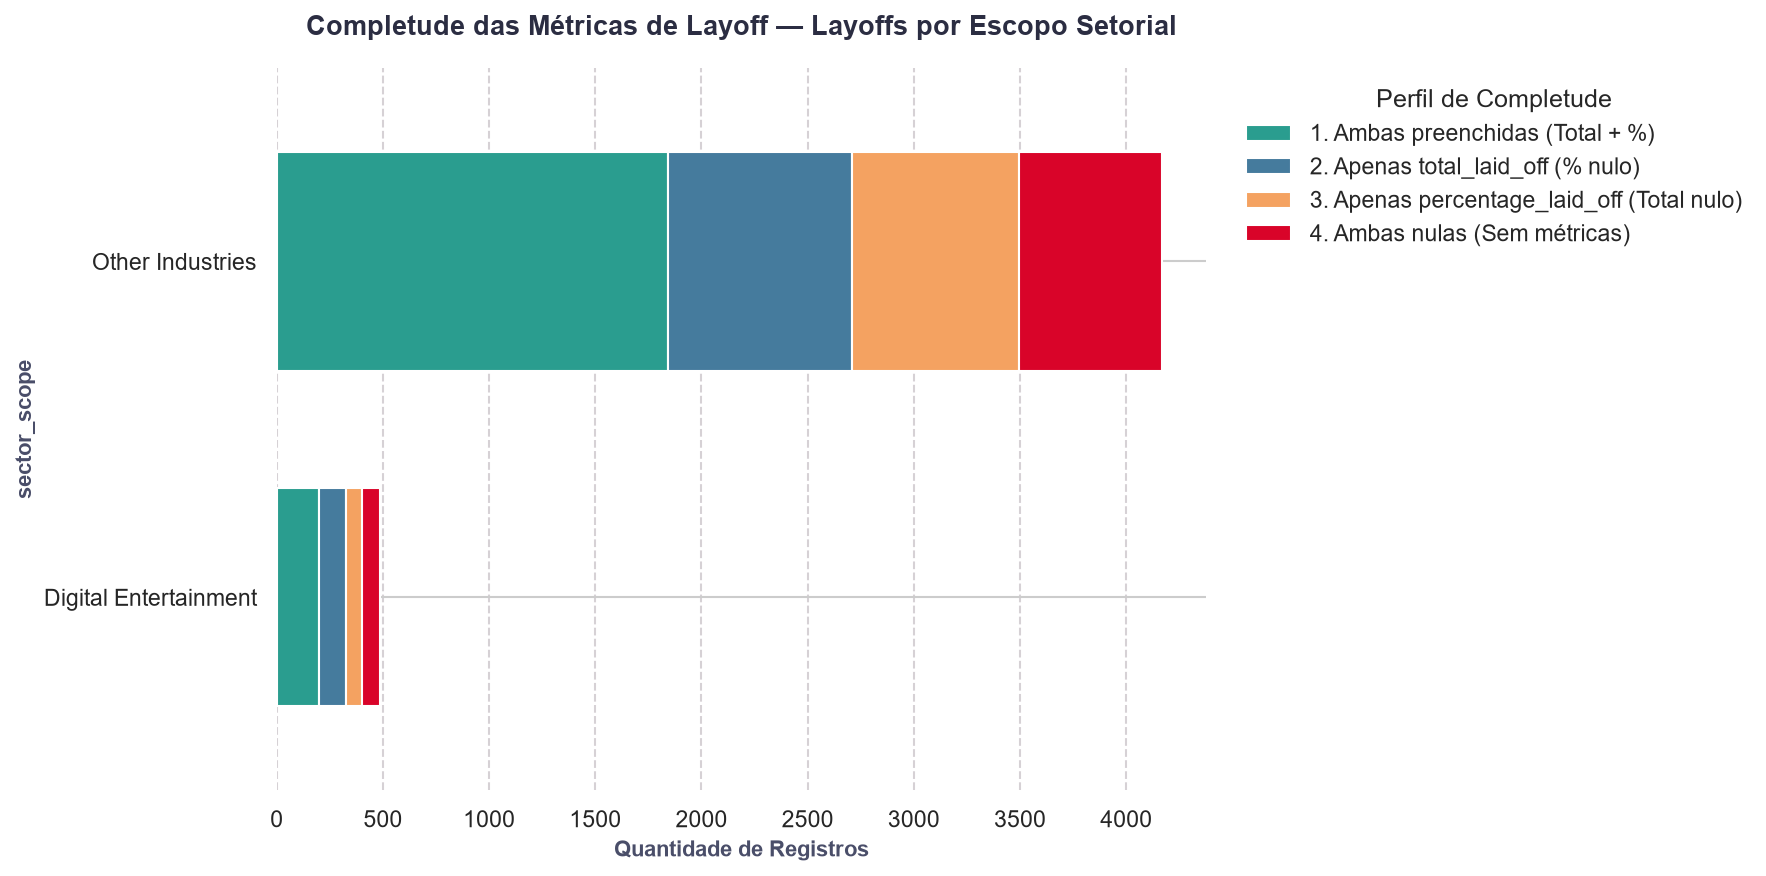

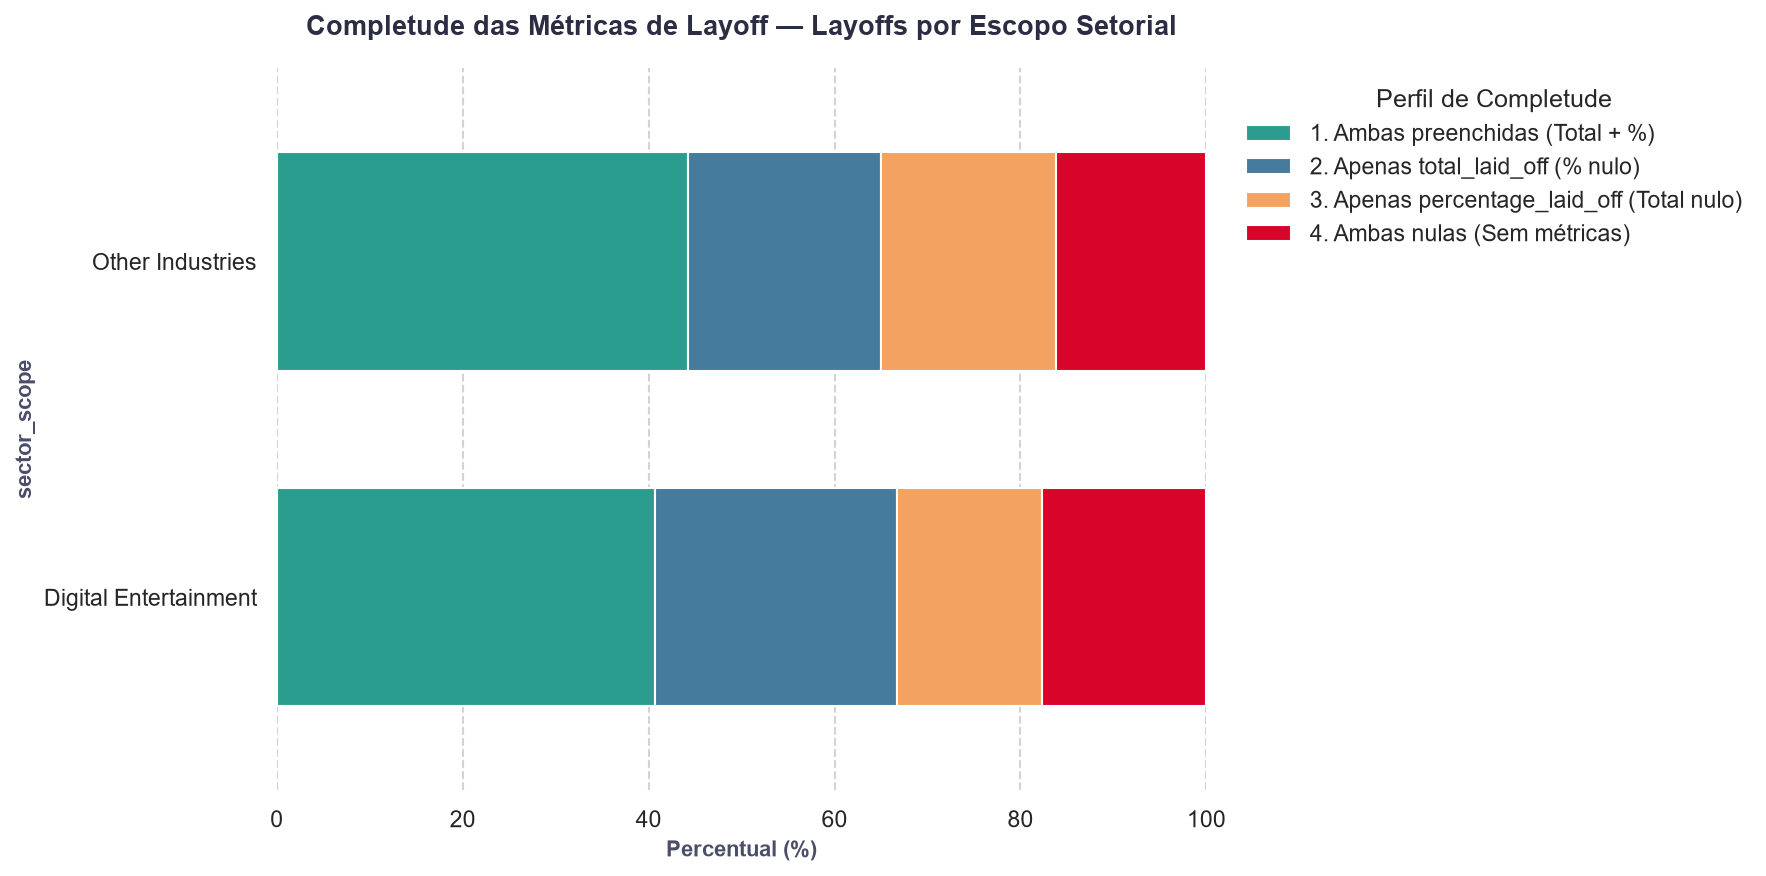

In [26]:
profile_table, percentage_table = cross_tabulation_sector_company(
    df_clean,
    column='sector_scope'
)

chart_completeness_profile(
    profile_table,
    percentage=False,
    dataframe_name='Layoffs por Escopo Setorial'
)

chart_completeness_profile(
    percentage_table,
    percentage=True,
    dataframe_name='Layoffs por Escopo Setorial',
    save_path="../docs/figures/cleaning/completeness_profile_sector_scope.png"
)

##### Por `industry`

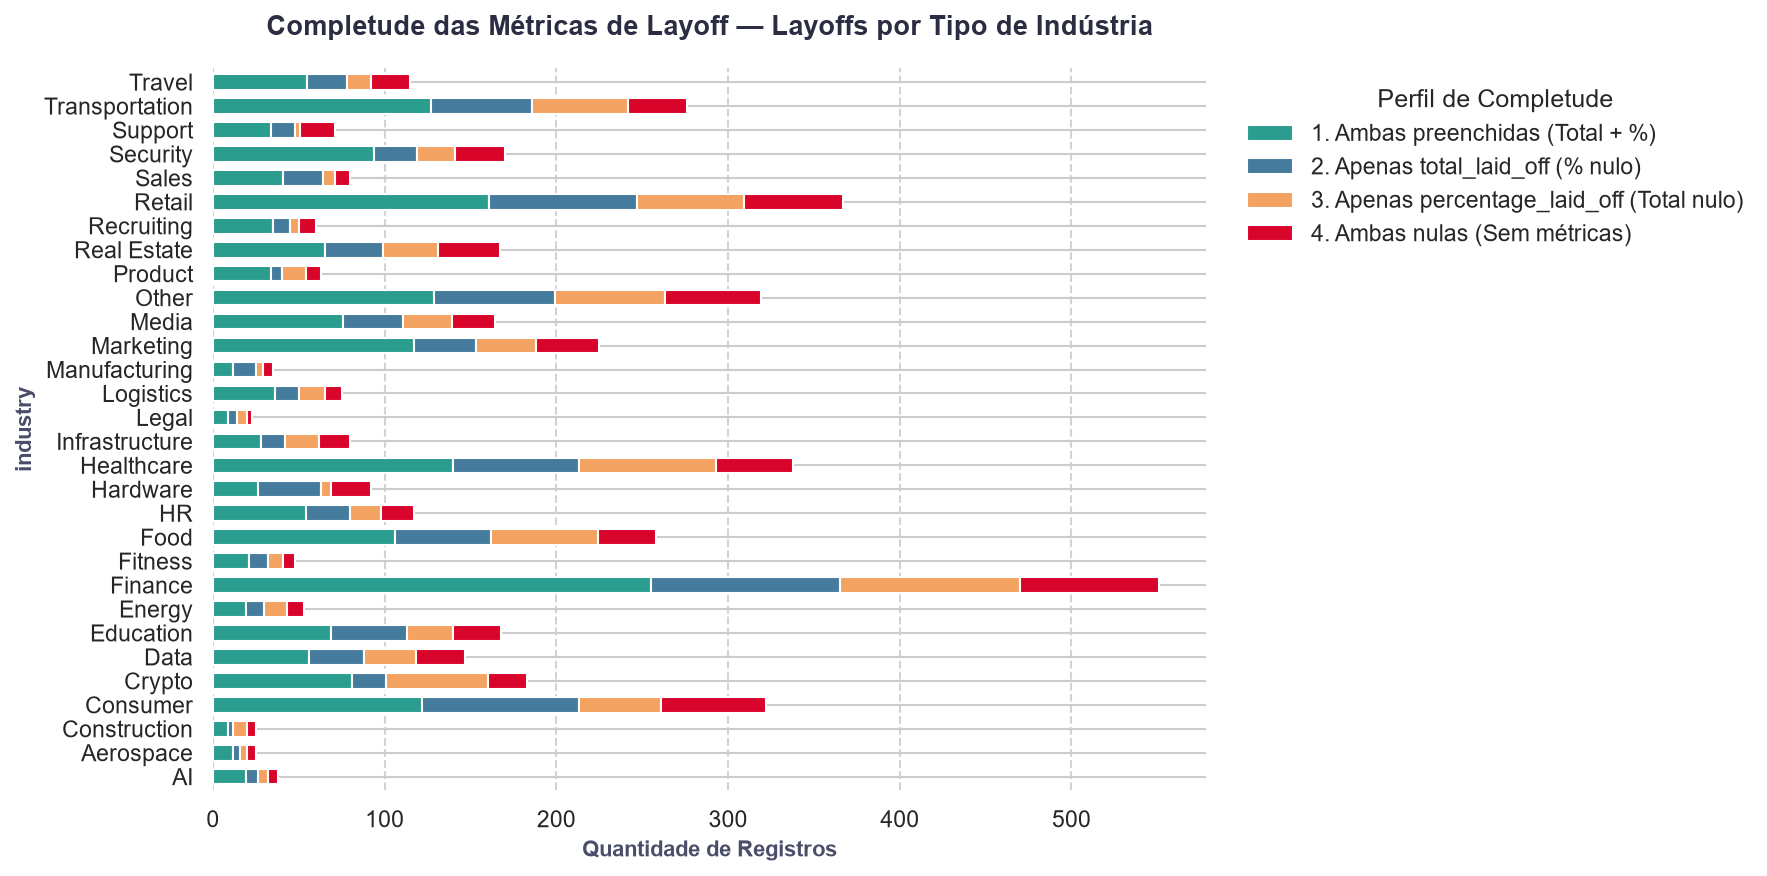

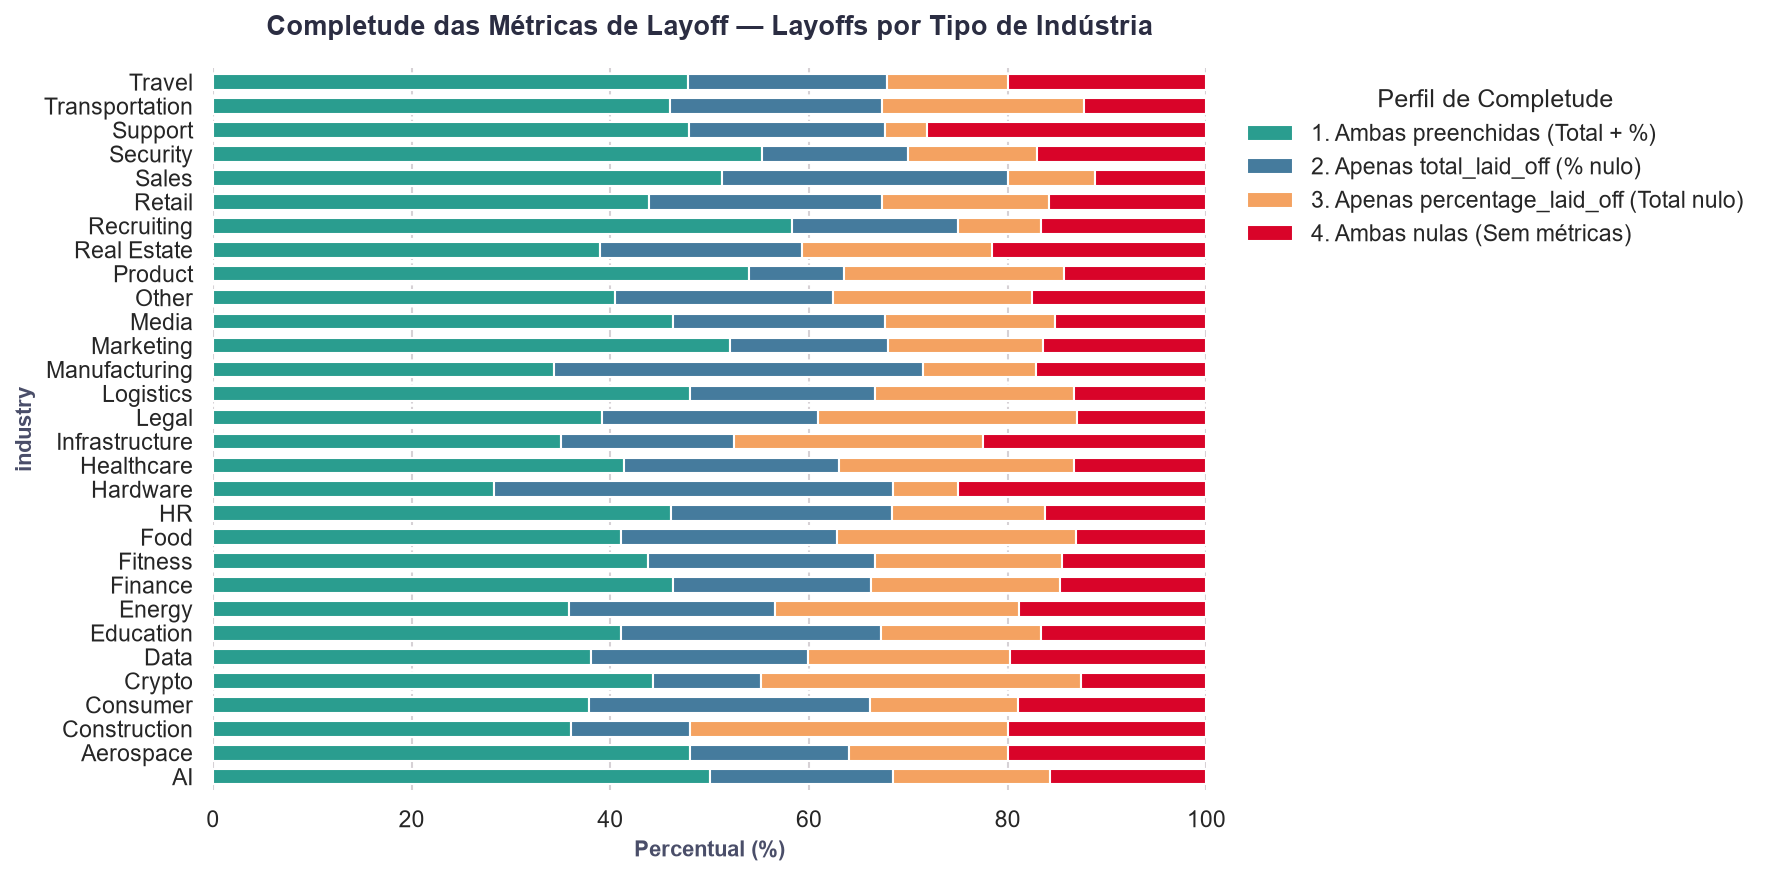

In [27]:
profile_table, percentage_table = cross_tabulation_sector_company(
    df_clean,
    column='industry'
)

chart_completeness_profile(
    profile_table,
    percentage=False,
    dataframe_name='Layoffs por Tipo de Indústria'
)

chart_completeness_profile(
    percentage_table,
    percentage=True,
    dataframe_name='Layoffs por Tipo de Indústria'
)

##### Por `stage`

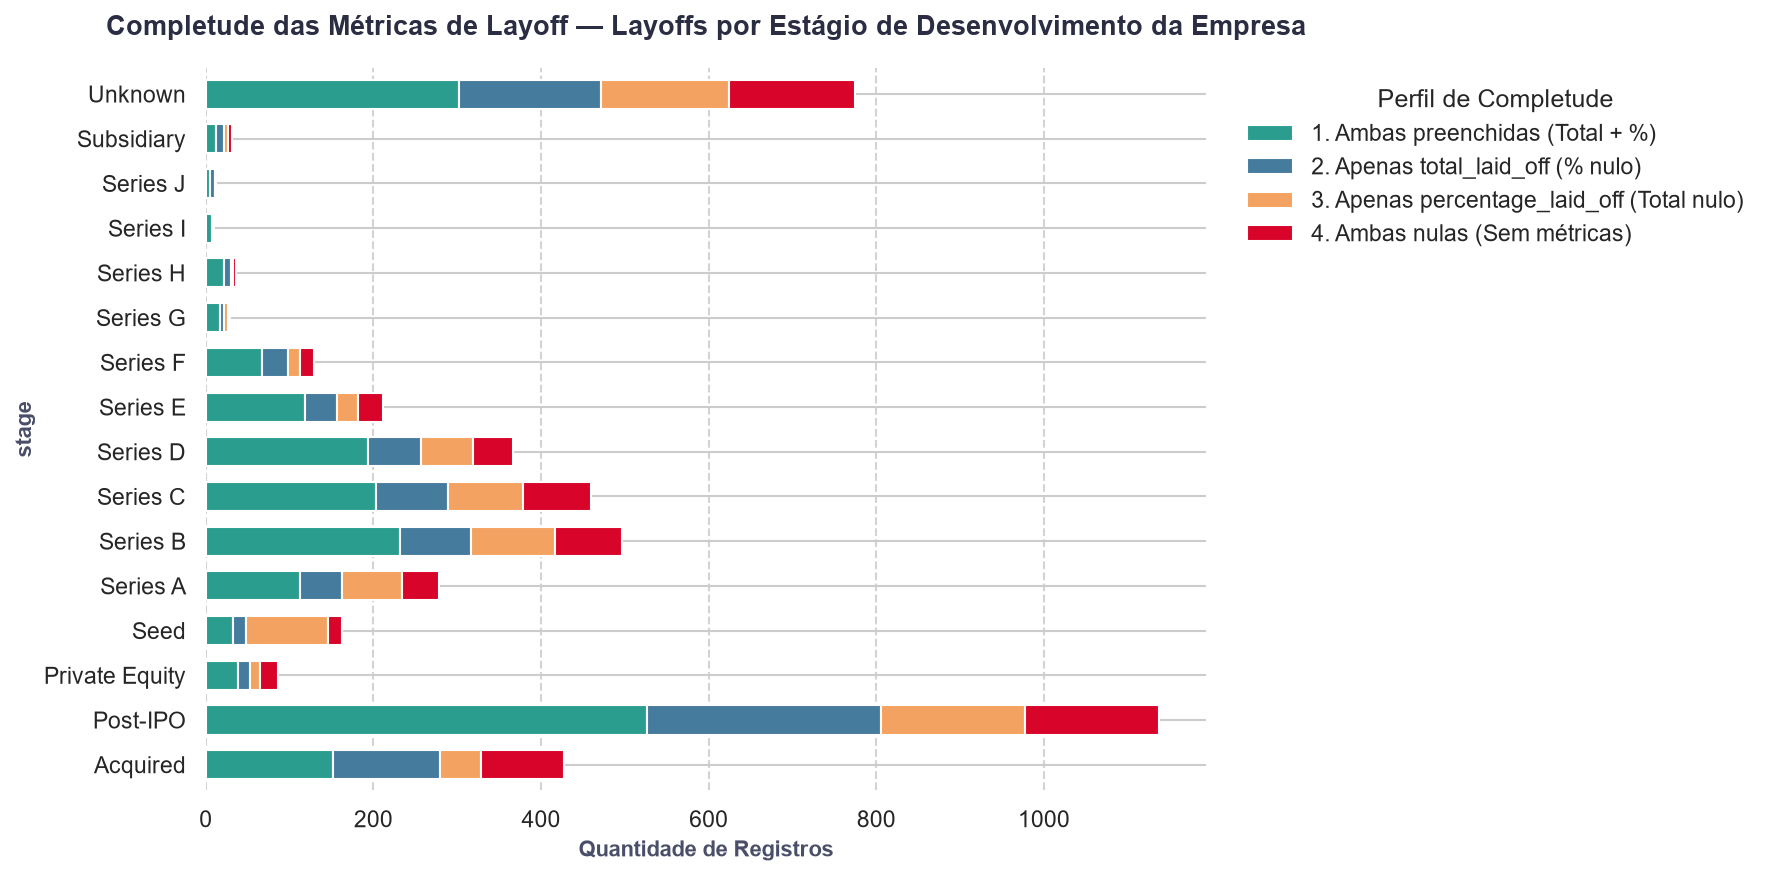

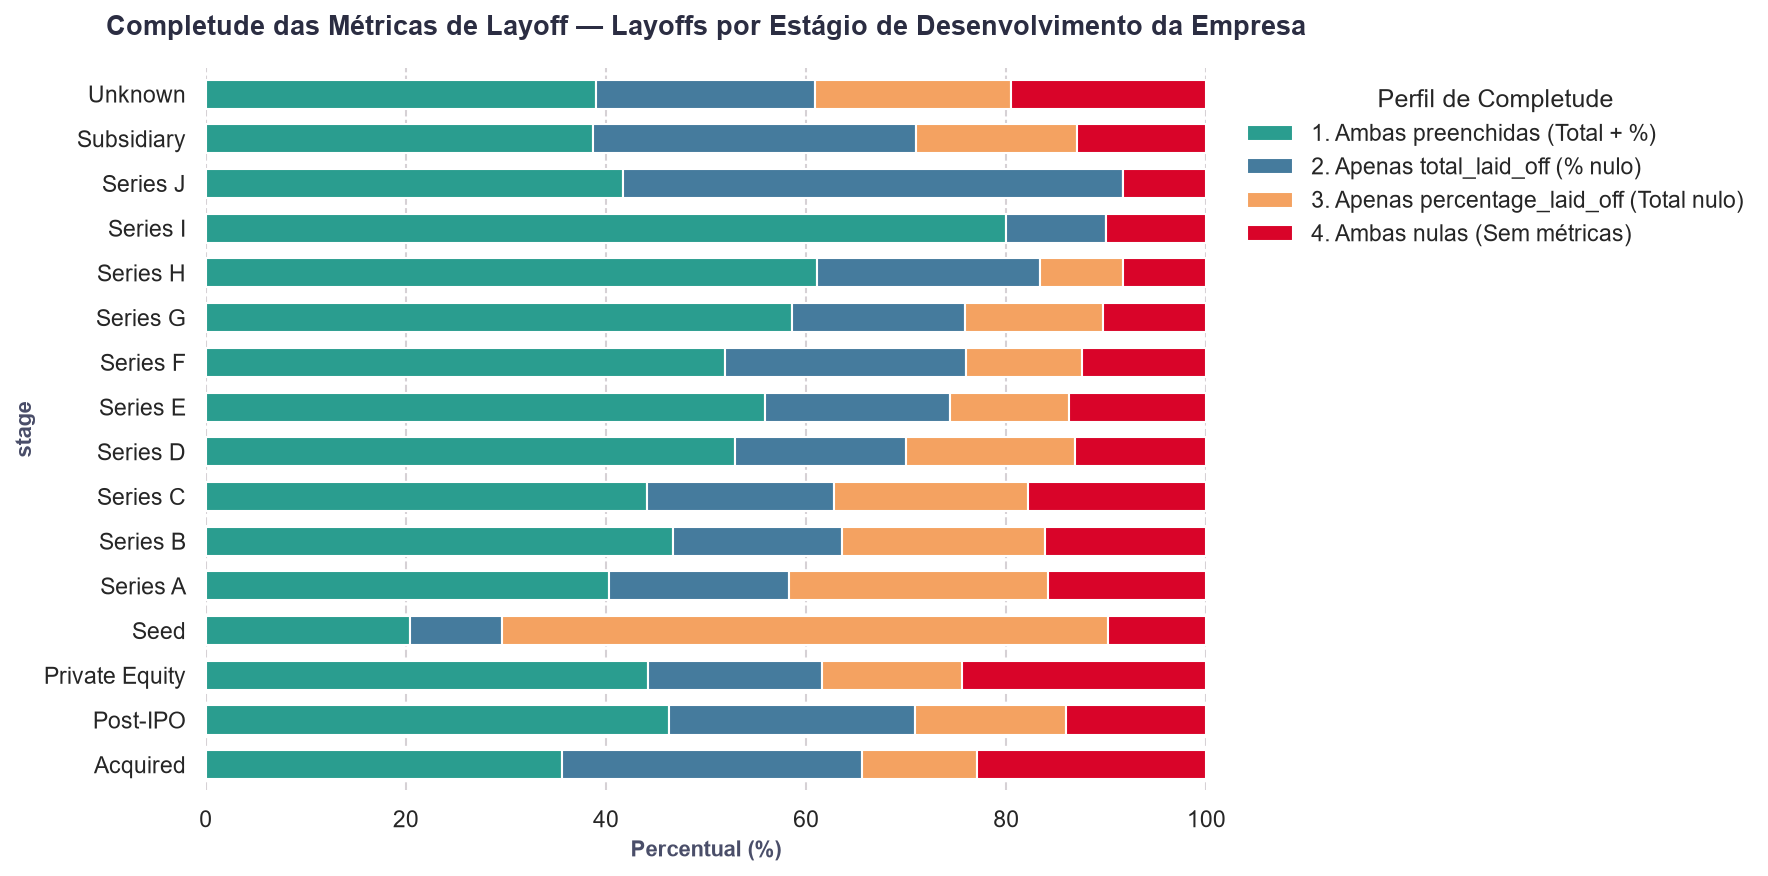

In [28]:
profile_table, percentage_table = cross_tabulation_sector_company(
    df_clean,
    column='stage'
)

chart_completeness_profile(
    profile_table,
    percentage=False,
    dataframe_name='Layoffs por Estágio de Desenvolvimento da Empresa'
)

chart_completeness_profile(
    percentage_table,
    percentage=True,
    dataframe_name='Layoffs por Estágio de Desenvolvimento da Empresa',
    save_path="../docs/figures/cleaning/completeness_profile_stage.png"
)

### Diagnóstico de Completude das Métricas de Layoff

A análise cruzada entre `total_laid_off` e `percentage_laid_off` evidencia três padrões estruturais na base:

* **Equilíbrio entre Escopos (`sector_scope`):** *Digital Entertainment* apresenta distribuição quase idêntica a *Other Industries* (~41% com ambas as métricas, ~26% apenas total absoluto, ~16% apenas percentual e ~17% sem métricas), descartando viés de subnotificação no setor alvo.
* **Assimetria por Maturidade (`stage`):** Startups em estágio *Seed* reportam majoritariamente apenas o percentual de corte (>60%), enquanto corporações *Post-IPO* e *Acquired* divulgam com muito mais frequência apenas o número absoluto de demitidos (25%–30%), omitindo o impacto percentual sobre o quadro global.
* **Perfil Interno (`Media` vs. `Consumer`):** *Media* concentra maior completude integral (~46%), ao passo que *Consumer* possui maior parcela com apenas o total absoluto (~28%), refletindo o peso de grandes empresas listadas em bolsa.

**Diretriz para Tratamento:** Os valores ausentes em `total_laid_off` e `percentage_laid_off` são estruturais (não aleatórios) e devem ser preservados como `NaN`, sem imputação estatística e sem exclusão de registros. Nas próximas etapas (engenharia de atributos / preparação para SQL e Power BI), criaremos uma coluna categórica `metric_completeness` com os 4 perfis mapeados (`Complete`, `Total Only`, `Percentage Only`, `No Metrics`), permitindo segmentar e filtrar rapidamente os visuais sem precisar reescrever condições de nulidade.

---

#### Nulos em `funds_raised`

In [29]:
# Amostra visual dos nulos em funds_raised
display(df_clean[df_clean['funds_raised'].isna()][
    ['company', 'stage', 'industry', 'country', 'sector_scope']
].head(15))

,company,stage,industry,country,sector_scope
0,Qualcomm,Post-IPO,Hardware,India,Other Industries
14,Nice,Unknown,Support,Israel,Other Industries
17,SUSE,Acquired,Infrastructure,Germany,Other Industries
21,Innodata,Post-IPO,Data,India,Other Industries
30,Vermont Information Processing,Acquired,Food,United States,Other Industries
35,Qualcomm,Post-IPO,Hardware,United States,Other Industries
65,Oracle,Post-IPO,Other,United States,Other Industries
67,Bitcoin Suisse,Series A,Crypto,Switzerland,Other Industries
71,Samsung,Post-IPO,Hardware,India,Other Industries
77,Orionx,Series A,Crypto,Chile,Other Industries


In [30]:
# Taxa de nulidade de funds_raised por escopo e estágio (top 8 estágios com mais nulos)
print("Nulos em funds_raised por sector_scope (%):")

print((df_clean['funds_raised'].isna().groupby(df_clean['sector_scope']).mean() * 100).round(2))


Nulos em funds_raised por sector_scope (%):
sector_scope
Digital Entertainment   16.87
Other Industries        11.30
Name: funds_raised, dtype: float64


In [31]:
print("\nNulos em funds_raised por stage (contagem e %):")

summary_funds_stage = (
    df_clean.groupby('stage')['funds_raised']
    .agg(total='size', nulos=lambda s: s.isna().sum())
    .assign(pct_nulos=lambda d: (d['nulos'] / d['total'] * 100).round(2))
    .sort_values('nulos', ascending=False)
)

display(summary_funds_stage.head(8))


Nulos em funds_raised por stage (contagem e %):


,total,nulos,pct_nulos
stage,,,
Unknown,775,220,28.39
Post-IPO,1137,131,11.52
Acquired,427,100,23.42
Seed,162,28,17.28
Subsidiary,31,19,61.29
Series A,278,14,5.04
Private Equity,86,11,12.79
Series B,497,8,1.61


In [32]:
# Checa se alguma empresa tem funds_raised preenchido em uma linha e nulo em outra
recoverable_companies = (
    df_clean.groupby('company')['funds_raised']
    .agg(n_nulos=lambda s: s.isna().sum(), n_validos=lambda s: s.notna().sum())
    .query('n_nulos > 0 and n_validos > 0')
)

print(
    "\nEmpresas com funds_raised parcialmente preenchido (recuperável entre registros): "
    + str(len(recoverable_companies))
)
if not recoverable_companies.empty:
    display(recoverable_companies)


Empresas com funds_raised parcialmente preenchido (recuperável entre registros): 18


,n_nulos,n_validos
company,,
Akerna,1,1
Astra,1,3
Bark,1,1
Bolt,1,4
C6 Bank,1,1
Cogito,1,1
Crypto.com,2,3
Dapper Labs,1,2
Fi.Money,1,1


In [33]:
# Inspeciona todos os registros das 18 empresas com funds_raised parcialmente preenchido
cols_inspection = ['company', 'date', 'industry', 'country', 'stage', 'funds_raised', 'sector_scope']

display(
    df_clean[df_clean['company'].isin(recoverable_companies.index)]
    .sort_values(['company', 'date'])
    [cols_inspection]
)

,company,date,industry,country,stage,funds_raised,sector_scope
3848,Akerna,5/27/2022,Logistics,United States,Unknown,46.00,Other Industries
4056,Akerna,9/2/2020,Logistics,United States,Post-IPO,NaN,Other Industries
3070,Astra,11/8/2022,Aerospace,United States,Post-IPO,300.00,Other Industries
4460,Astra,4/5/2020,Aerospace,United States,Unknown,100.00,Other Industries
533,Astra,7/28/2025,Sales,India,Unknown,NaN,Other Industries
1730,Astra,8/4/2023,Aerospace,United States,Post-IPO,300.00,Other Industries
2405,Bark,2/9/2023,Retail,United States,Post-IPO,NaN,Other Industries
1817,Bark,7/13/2023,Retail,United States,Post-IPO,282.00,Other Industries
2546,Bolt,1/24/2023,Finance,United States,Series E,1300.00,Other Industries
1393,Bolt,12/14/2023,Finance,United States,Series E,1300.00,Other Industries


### Diagnóstico de Valores Ausentes em `funds_raised`

A análise dos registros sem informação de captação financeira (`16,87%` em *Digital Entertainment* e `11,30%` em *Other Industries*) confirma um padrão estrutural associado ao perfil corporativo:

* **Concentração por Estágio (`stage`):** Os nulos concentram-se majoritariamente em empresas classificadas como *Subsidiary* (`61,29%`), *Unknown* (`28,39%`), *Acquired* (`23,42%`), *Seed* (`17,28%`) e *Post-IPO* (`11,52%`), que frequentemente operam sem rodadas de venture capital divulgadas ou com estruturas societárias fechadas.
* **Inviabilidade de Propagação entre Registros:** Embora existam 18 nomes de empresas com valores parcialmente preenchidos na base, a inspeção detalhada identificou **empresas homônimas** atuando em países e setores distintos (como *Bolt*, *Unity*, *Astra*, *Tomorrow* e *Cogito*), além da evolução natural do volume captado ao longo dos anos conforme novas rodadas ocorrem.

**Diretriz para Tratamento:** Para evitar tanto a mistura de empresas homônimas quanto anacronismos entre diferentes rodadas de investimento, a propagação de `funds_raised` será aplicada **exclusivamente** entre registros que compartilhem exatamente a mesma **`company`, `country` e `stage` conhecido** (excluindo `'Unknown'`). Os demais valores ausentes serão preservados como `NaN`, sem imputação estatística ou por zero.

---

### 3.4 Tratamento Inicial de Valores Ausentes

In [34]:
# Propaga funds_raised apenas quando company, country e stage (conhecido) são idênticos
mask_stage_valid = (
    df_clean['stage'].notna() & 
    (df_clean['stage'] != 'Unknown')
)

funds_recuperados = (
    df_clean[mask_stage_valid]
    .groupby(['company', 'country', 'stage'])['funds_raised']
    .transform('first')
)

after_funds = df_clean['funds_raised'].notna().sum()

df_clean.loc[mask_stage_valid, 'funds_raised'] = df_clean.loc[
        mask_stage_valid, 'funds_raised'
].fillna(funds_recuperados)

depois_funds = df_clean['funds_raised'].notna().sum()


print(f"Registros de funds_raised recuperados deterministicamente: {depois_funds - after_funds}")

Registros de funds_raised recuperados deterministicamente: 5


### 3.5 Exploração de Valores Ausentes Pontuais

In [35]:
# Inspeciona os registros com nulos pontuais ou valor zero anômalo
mask_punctual = (
    df_clean['stage'].isna() |
    df_clean['source'].isna() |
    df_clean['country'].isna() |
    df_clean['location'].isna() 
)

print(f"Total de registros com nulos pontuais ou anomalia zero: {mask_punctual.sum()}")
display(df_clean[mask_punctual])

Total de registros com nulos pontuais ou anomalia zero: 14


,company,location,total_laid_off,date,percentage_laid_off,industry,source,stage,funds_raised,country,date_added,sector_scope
280,Zondacrypto,"Tallinn, Non-U.S.",NaN,4/21/2026,NaN,Crypto,https://tvpworld.com/92834466/zonadcrypto-staff-report-chaos-and-mass-layoffs,NaN,NaN,Estonia,7/13/2026,Other Industries
322,Flex AI,"Vancouver, Non-U.S.",NaN,3/24/2026,1.00,Fitness,https://betakit.com/personal-training-app-flex-ai-is-shutting-down/,NaN,NaN,Canada,7/27/2026,Other Industries
334,OP Labs,New York City,20.00,3/12/2026,NaN,Crypto,https://www.cryptotimes.io/2026/03/12/op-labs-lays-off-employees/,NaN,NaN,United States,7/13/2026,Other Industries
1558,Product Hunt,NaN,NaN,10/9/2023,0.60,Consumer,https://techcrunch.com/2023/10/19/product-hunt-cleans-house-with-layoffs-impacting-60-of-staff/,Acquired,NaN,United States,10/15/2023,Digital Entertainment
1592,Fit Analytics,"Berlin, Non-U.S.",NaN,9/28/2023,1.00,Retail,https://www.businessinsider.de/gruenderszene/technologie/nach-uebernahme-snap-kuendigt-allen-mit...,Acquired,NaN,NaN,9/29/2023,Other Industries
1846,Trellix,SF Bay Area,NaN,7/7/2023,NaN,Security,NaN,Unknown,35.00,United States,7/11/2023,Other Industries
1876,Ludia,"Montreal, Non-U.S.",55.00,6/28/2023,NaN,Consumer,https://mobilegamer.biz/up-to-55-staff-laid-off-at-jurassic-world-alive-maker-ludia/,Acquired,1.00,NaN,6/30/2023,Digital Entertainment
2523,Soundwide,"Berlin, Non-U.S.",NaN,1/27/2023,0.08,Other,https://cdm.link/2023/01/soundwide-layoffs/,NaN,NaN,Germany,5/1/2023,Other Industries
2820,N-able Technologies,Raleigh,NaN,12/9/2022,NaN,Other,NaN,Post-IPO,225.00,United States,12/9/2022,Other Industries
3132,Advata,Seattle,32.00,10/28/2022,0.21,Healthcare,https://www.geekwire.com/2022/seattle-area-health-data-analytics-company-advata-lays-off-employees/,NaN,NaN,United States,10/31/2022,Other Industries


#### Observando Mais de Perto Registros com Cidade,  mas Nulos em `country` 

In [36]:
target_cities = ['Berlin, Non-U.S.', 'Montreal, Non-U.S.']

display(
    df_clean[df_clean['location'].isin(target_cities)]
    .groupby(['location', 'country'], dropna=False)
    .size()
    .to_frame(name='qtd_registros')
)

qtd_registros
location           country               
Berlin, Non-U.S.   Germany             99
                   NaN                  1
Montreal, Non-U.S. Canada              27
                   NaN                  1

#### Verificar o domínio de valores existentes em stage e source

In [37]:
stage_dist = (
    df_clean['stage']
    .fillna('Nulo (NaN)')
    .value_counts()
    .to_frame(name='registros')
    .assign(percentual=lambda d: (d['registros'] / len(df_clean) * 100).round(2))
)
stage_dist.index.name = 'stage'

display(stage_dist)

,registros,percentual
stage,,
Post-IPO,1137,24.43
Unknown,775,16.65
Series B,497,10.68
Series C,460,9.88
Acquired,427,9.17
Series D,367,7.88
Series A,278,5.97
Series E,211,4.53
Seed,162,3.48


In [38]:
source_dist = (
    df_clean['source']
    .fillna('Nulo (NaN)')
    .apply(lambda x: 'URL (http/https)' if str(x).startswith('http') else x)
    .value_counts()
)

# Garante que 'Unknown' apareça explicitamente na exibição mesmo com 0 ocorrências antes do tratamento
if 'Unknown' not in source_dist.index:
    source_dist.loc['Unknown'] = 0

source_dist = (
    source_dist
    .sort_values(ascending=False)
    .to_frame(name='registros')
    .assign(percentual=lambda d: (d['registros'] / len(df_clean) * 100).round(2))
)
source_dist.index.name = 'tipo_source'

display(source_dist)

,registros,percentual
tipo_source,,
URL (http/https),4466,95.94
Internal memo,107,2.30
LinkedIn,62,1.33
Company exec,7,0.15
Company executive,6,0.13
Nulo (NaN),3,0.06
8/28/solana-based-automation-startup-clockwork-to-shut-down/,1,0.02
Times Internet,1,0.02
Read more at:,1,0.02


In [39]:
# Inspeciona os 2 ruídos textuais em source
display(df_clean[df_clean['source'].isin([
    '8/28/solana-based-automation-startup-clockwork-to-shut-down/',
    'Read more at:'
])])

,company,location,total_laid_off,date,percentage_laid_off,industry,source,stage,funds_raised,country,date_added,sector_scope
1667,Clockwork,Dallas,NaN,8/28/2023,1.00,Crypto,8/28/solana-based-automation-startup-clockwork-to-shut-down/,Seed,4.00,United States,8/28/2023,Other Industries
1839,FrontRow,"Bengaluru, Non-U.S.",NaN,7/10/2023,1.00,Education,Read more at:,Series A,17.00,India,7/11/2023,Other Industries


### Diagnóstico e Plano de Tratamento dos Valores Ausentes Pontuais

A auditoria dos 14 registros com valores ausentes em atributos categóricos e geográficos (`stage`, `source`, `country` e `location`) demonstrou que todos os casos podem ser resolvidos de forma determinística ou padronizada sem exclusão de linhas:

* **Geografia (`country` — 2 registros):** As cidades informadas apresentam mapeamento unívoco no restante do conjunto de dados (`Berlin, Non-U.S.` corresponde a `Germany` em 99 de 99 registros válidos; `Montreal, Non-U.S.` corresponde a `Canada` em 27 de 27 registros válidos). Assim, os nulos em *Fit Analytics* e *Ludia* serão preenchidos deterministicamente.
* **Localização (`location` — 1 registro):** O registro ausente (*Product Hunt*) não possui outra ocorrência na base para propagação geográfica e será preenchido como `'Unknown'`.
* **Estágio de Investimento (`stage` — 8 registros):** A categoria `'Unknown'` já integra o domínio nativo do dataset (`16,65%` dos registros). Os 8 nulos pontuais (`0,17%`) serão atribuídos a `'Unknown'`, uma vez que outros registros das mesmas empresas em datas distintas não garantem o mesmo estágio histórico.
* **Fonte do Registro (`source` — 3 registros):** Os 3 valores ausentes serão preenchidos como `'Unknown'`, mantendo a integridade cadastral das ocorrências sem descartar eventos documentados.
  
<br>

---

### 3.6 Tratando de Valores Ausentes Pontuais

#### Recuperação determinística de `country` a partir de `location`

In [40]:
# Mapeamento unívoco validado na Seção 3.3 (99/99 Berlin -> Germany; 27/27 Montreal -> Canada)
city_country_map = {
    'Berlin, Non-U.S.': 'Germany',
    'Montreal, Non-U.S.': 'Canada'
}

df_clean['country'] = df_clean['country'].fillna(df_clean['location'].map(city_country_map))

assert df_clean['country'].isna().sum() == 0, "Falha: ainda existem nulos em 'country'"

print("Nulos em 'country' recuperados com sucesso.")

Nulos em 'country' recuperados com sucesso.


#### Preenchimento dos nulos pontuais em `location` e `stage`

In [41]:
# Preserva o domínio nativo do dataset atribuindo 'Unknown' aos casos sem registro
df_clean['location'] = df_clean['location'].fillna('Unknown')
df_clean['stage'] = df_clean['stage'].fillna('Unknown')

assert df_clean['location'].isna().sum() == 0, "Falha: ainda existem nulos em 'location'"

assert df_clean['stage'].isna().sum() == 0, "Falha: ainda existem nulos em 'stage'"

print("Nulos em 'location' e 'stage' padronizados como 'Unknown'.")

Nulos em 'location' e 'stage' padronizados como 'Unknown'.


#### Higienização e preenchimento dos nulos em `source`

In [42]:
# Remove espaços laterais, padroniza sinônimos/fragmentos e preenche os 3 nulos como 'Unknown'
df_clean['source'] = (
    df_clean['source']
    .str.strip()
    .replace({
        'Company exec': 'Company executive',
        '8/28/solana-based-automation-startup-clockwork-to-shut-down/': 'Unknown',
        'Read more at:': 'Unknown'
    })
    .fillna('Unknown')
)

assert df_clean['source'].isna().sum() == 0, "Falha: ainda existem nulos em 'source'"

print("Coluna 'source' higienizada e nulos preenchidos com 'Unknown'.")

Coluna 'source' higienizada e nulos preenchidos com 'Unknown'.


#### Checando DataFrame Pós Tratamento

In [43]:
# Gerar relatório de qualidade dos dados
qa_report = check_data_quality(df_clean)
display(qa_report)

,Quantidade,Incidência (%)
percentage_laid_off (Nulos/NaN),1751,37.62
total_laid_off (Nulos/NaN),1621,34.82
funds_raised (Nulos/NaN),548,11.77
Duplicidade Parcial (Mesma Empresa + Data),5,0.11


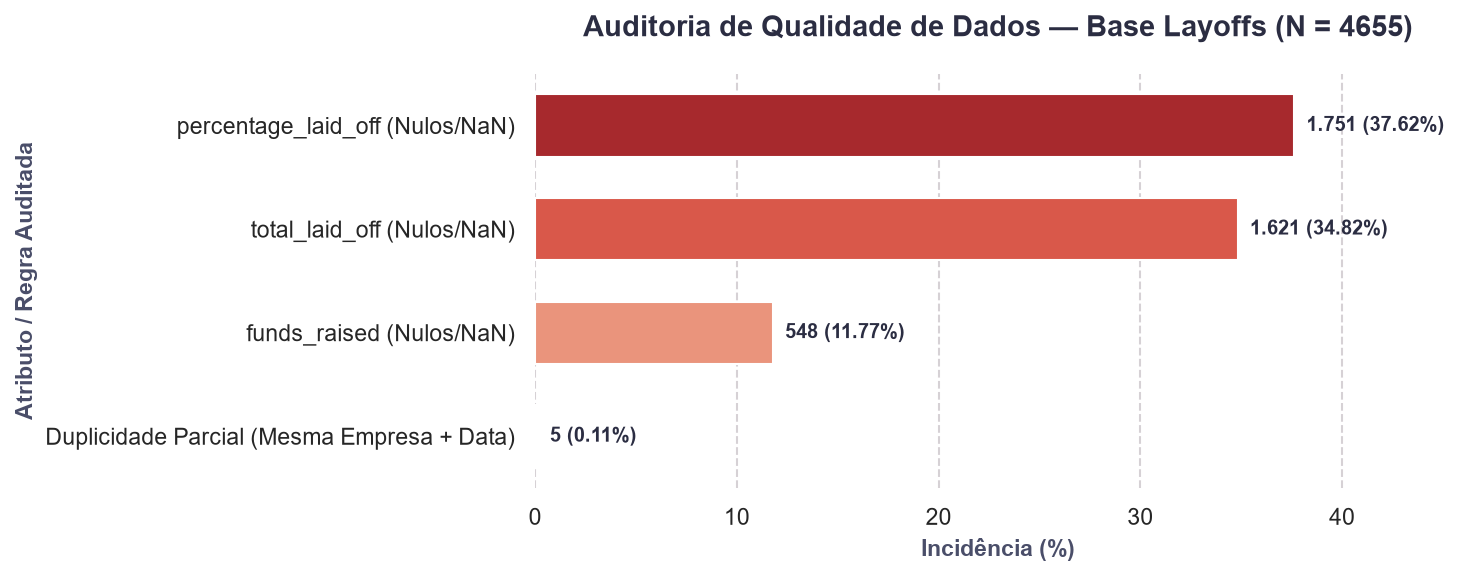

In [44]:
# Visualizar o relatório de qualidade dos dados
chart_data_quality(
    qa_report, 
    name_df=f"Base Layoffs (N = {len(df_clean)})", 
)

## 4. Padranização Geográfica e Categórica

### 4.1. Auditoria Geográfica e Categórica

In [48]:
# Auditoria de valores únicos e potenciais inconsistências em colunas geográficas e categóricas
for col in ['country', 'industry', 'stage']:
    print(f"\n=== {col.upper()} ({df_clean[col].nunique()} únicos) ===")
    display(pd.DataFrame(sorted(df_clean[col].unique()), columns=[col]))


=== COUNTRY (67 únicos) ===


,country
0,Argentina
1,Australia
2,Austria
3,Bahrain
4,Belgium
...,...
62,United Arab Emirates
63,United Kingdom
64,United States
65,Uruguay



=== INDUSTRY (30 únicos) ===


,industry
0,AI
1,Aerospace
2,Construction
3,Consumer
4,Crypto
5,Data
6,Education
7,Energy
8,Finance
9,Fitness



=== STAGE (16 únicos) ===


,stage
0,Acquired
1,Post-IPO
2,Private Equity
3,Seed
4,Series A
5,Series B
6,Series C
7,Series D
8,Series E
9,Series F


In [49]:
# Verifica padrões de sufixos em 'location' (ex: ', Non-U.S.', espaços extras, duplicidades de nome)
print(f"=== LOCATION ({df_clean['location'].nunique()} únicos) ===")
display(
    df_clean['location']
    .value_counts()
    .to_frame(name='registros')
    .head(25)
)

=== LOCATION (275 únicos) ===


,registros
location,
SF Bay Area,1157
New York City,458
Seattle,207
"Bengaluru, Non-U.S.",201
Boston,197
"Tel Aviv, Non-U.S.",177
Los Angeles,171
"London, Non-U.S.",141
"Berlin, Non-U.S.",100


In [51]:
# Exibe todos os 67 países sem truncamento
print("Todos os valores únicos de 'country':")
country = df_clean['country'].sort_values().unique().tolist()
for index, value in enumerate(country):
    print(f"{index + 1:02d}. {value}")

Todos os valores únicos de 'country':
01. Argentina
02. Australia
03. Austria
04. Bahrain
05. Belgium
06. Brazil
07. Bulgaria
08. Canada
09. Cayman Islands
10. Chile
11. China
12. Colombia
13. Cyprus
14. Czech Republic
15. Denmark
16. Egypt
17. Estonia
18. Finland
19. France
20. Germany
21. Ghana
22. Greece
23. Hong Kong
24. Hungary
25. India
26. Indonesia
27. Ireland
28. Israel
29. Italy
30. Japan
31. Kenya
32. Lithuania
33. Luxembourg
34. Malaysia
35. Malta
36. Mexico
37. Morocco
38. Myanmar
39. Netherlands
40. New Zealand
41. Nigeria
42. Norway
43. Pakistan
44. Peru
45. Philippines
46. Poland
47. Portugal
48. Romania
49. Russia
50. Saudi Arabia
51. Senegal
52. Seychelles
53. Singapore
54. South Africa
55. South Korea
56. Spain
57. Sweden
58. Switzerland
59. Thailand
60. Turkey
61. UAE
62. Ukraine
63. United Arab Emirates
64. United Kingdom
65. United States
66. Uruguay
67. Vietnam


In [54]:
# Audita espaços laterais ou múltiplos espaços internos nas colunas categóricas
cols_text = ['company', 'location', 'industry', 'stage', 'source', 'country']
for col in cols_text:
    side_spaces = (df_clean[col] != df_clean[col].str.strip()).sum()
    double_spaces = df_clean[col].str.contains(r'\s{2,}', regex=True).sum()
    if side_spaces > 0 or double_spaces > 0:
        print(f"Coluna '{col}': {side_spaces} com espaços laterais | {double_spaces} com espaços duplos")

Coluna 'company': 16 com espaços laterais | 0 com espaços duplos


In [ ]:
def normalize_key(texto):
    no_suffix = str(texto).replace(', Non-U.S.', '').strip().lower()
    without_accent = ''.join(
        c for c in unicodedata.normalize('NFKD', no_suffix)
        if not unicodedata.combining(c)
    )
    return without_accent

loc_audit = (
    df_clean.groupby(['location', 'country'])
    .size()
    .reset_index(name='registros')
)
loc_audit['chave_base'] = loc_audit['location'].apply(normalize_key)

# Filtra cidades que possuem mais de uma grafia (com/sem acento, com/sem Non-U.S., ou países conflitantes)
duplicadas_loc = loc_audit[loc_audit.duplicated('chave_base', keep=False)].sort_values('chave_base')
print(f"Variações encontradas em 'location': {len(duplicadas_loc)} linhas")
display(duplicadas_loc)

Variações encontradas em 'location': 52 linhas


,location,country,registros,chave_base
19,Bengaluru,India,4,bengaluru
20,"Bengaluru, Non-U.S.",India,201,bengaluru
27,Boston,Germany,1,boston
28,Boston,United States,196,boston
31,Brisbane,United States,1,brisbane
32,"Brisbane, Non-U.S.",Australia,9,brisbane
38,Buenos Aires,Argentina,1,buenos aires
39,"Buenos Aires, Non-U.S.",Argentina,5,buenos aires
40,"Buenos Aires, Non-U.S.",Brazil,1,buenos aires
47,Cayman Islands,Cayman Islands,1,cayman islands


In [60]:
comp_audit = (
    df_clean.groupby('company')
    .size()
    .reset_index(name='registros')
)
comp_audit['key_lower'] = comp_audit['company'].str.strip().str.lower()

duplicadas_comp = comp_audit[comp_audit.duplicated('key_lower', keep=False)].sort_values('key_lower')
print(f"Variações de escrita/caixa em 'company': {len(duplicadas_comp)} linhas")
display(duplicadas_comp)

Variações de escrita/caixa em 'company': 34 linhas


,company,registros,key_lower
14,7Shifts,1,7shifts
15,7shifts,1,7shifts
147,AppGate,1,appgate
151,Appgate,1,appgate
504,Character.AI,1,character.ai
505,Character.ai,1,character.ai
551,ClearCo,1,clearco
555,Clearco,3,clearco
1023,Freshbooks,1,freshbooks
1021,FreshBooks,4,freshbooks


In [58]:
# Inspeciona os conflitos geográficos (cidade de um país associada a outro) e 'Non-U.S.' puro
conflicts_geo = [
    ('Boston', 'Germany'),
    ('Brisbane', 'United States'),
    ('Buenos Aires, Non-U.S.', 'Brazil'),
    ('Dublin, Non-U.S.', 'United States'),
    ('Haifa, Non-U.S.', 'United States'),
    ('Jakarta, Non-U.S.', 'India'),
    ('Jerusalem, Non-U.S.', 'United States'),
    ('New York City', 'France'),
    ('New York City', 'Israel'),
    ('Oslo, Non-U.S.', 'Sweden'),
    ('SF Bay Area', 'Israel'),
    ('Tel Aviv, Non-U.S.', 'United States'),
    ('Vancouver, Non-U.S.', 'United States')
]

mask_conflicts = df_clean.set_index(['location', 'country']).index.isin(conflicts_geo)
mask_non_us = df_clean['location'] == 'Non-U.S.'

display(
    df_clean[mask_conflicts | mask_non_us]
    [['company', 'date', 'location', 'country', 'industry', 'source', 'sector_scope']]
    .sort_values(['location', 'country'])
)

,company,date,location,country,industry,source,sector_scope
647,Wayfair,3/7/2025,Boston,Germany,Retail,https://finance.yahoo.com/news/retailer-wayfair-restructures-technology-team-135556649.html,Other Industries
2657,Arch Oncology,1/13/2023,Brisbane,United States,Healthcare,https://endpts.com/scoop-roche-backed-startup-gives-up-on-cd47-as-ceo-most-employees-leave/,Other Industries
399,MercadoLibre,1/12/2026,"Buenos Aires, Non-U.S.",Brazil,Retail,https://eleconomista.com.ar/economia/despidos-mercado-libre-entrenamos-ia-nos-reemplazo-n91871,Other Industries
499,Salesforce,9/3/2025,"Dublin, Non-U.S.",United States,Sales,https://www.thejournal.ie/salesforce-ireland-redundancies-6806486-Sep2025/,Other Industries
284,Shutterfly,4/16/2026,"Haifa, Non-U.S.",United States,Manufacturing,https://www.calcalistech.com/ctechnews/article/rkx2avanzg,Other Industries
1471,Halodoc,11/14/2023,"Jakarta, Non-U.S.",India,Healthcare,https://www.techinasia.com/halodoc-lays-employees-pursue-sustainable-business-growth,Other Industries
457,Medtronic,10/27/2025,"Jerusalem, Non-U.S.",United States,Healthcare,https://www.calcalistech.com/ctechnews/article/s1g3z02cgg,Other Industries
825,Jellysmack,10/21/2024,New York City,France,Media,https://www.businessinsider.in/tech/news/jellysmack-is-laying-off-staff-as-it-scales-back-its-cr...,Digital Entertainment
559,Retrain.ai,7/2/2025,New York City,Israel,HR,https://www.calcalistech.com/ctechnews/article/s1avcuzhgg,Other Industries
3958,WeDoctor,3/2/2022,Non-U.S.,China,Healthcare,https://www.bloomberg.com/news/articles/2022-03-03/wedoctor-is-said-to-cut-workforce-after-delay...,Other Industries


#### Auditoria dos atributos textuais e geográficos 

A auditoria (`country`, `location`, `industry`, `stage` e `company`) revelou que os domínios de `industry` (30 categorias) e `stage` (16 categorias) já se encontram íntegros e sem sinônimos. Contudo, foram identificadas inconsistências de nomenclatura e conflitos espaciais que fragmentariam agregações analíticas e mapas geográficos:

* **Unificação de Nomenclatura de Países (`country`):** Presença de sigla duplicada para o mesmo país (`UAE` em 3 registros e `United Arab Emirates` em 7 registros), que será unificada como `'United Arab Emirates'`.

* **Resolução de Conflitos Cidade × País (16 registros):** Em eventos de empresas multinacionais, o dataset original registrou pontualmente o país da sede global ou de origem dos fundadores em vez do país da cidade onde o corte ocorreu (validado pelas fontes jornalísticas em `source`). Os registros serão alinhados ao local efetivo da operação (`Dublin` $\rightarrow$ `Ireland`, `Haifa`/`Jerusalem`/`Tel Aviv` $\rightarrow$ `Israel`, `Jakarta` $\rightarrow$ `Indonesia`, `Oslo` $\rightarrow$ `Norway`, `Vancouver` $\rightarrow$ `Canada`, `Buenos Aires` $\rightarrow$ `Argentina`, e `Boston`/`New York City`/`SF Bay Area` $\rightarrow$ `United States`, mantendo `Brisbane` nos EUA por referir-se a Brisbane, Califórnia).

* **Limpeza e Normalização de Cidades (`location`):** Remoção do sufixo redundante `', Non-U.S.'` (informação já representada pela coluna `country`), conversão do marcador genérico `'Non-U.S.'` sem cidade específica (4 registros) para `'Unknown'` e padronização de diacríticos duplicados para o formato ASCII da base (`Düsseldorf` $\rightarrow$ `Dusseldorf` e `Malmö` $\rightarrow$ `Malmo`).

* **Higienização e Padronização de Empresas (`company`):** Remoção de espaços em branco residuais nas extremidades (16 registros) e unificação de 11 pares de empresas duplicadas por variação de capitalização (como `TikTok`/`Tiktok`, `HubSpot`/`Hubspot`, `UiPath`/`UIPath` e `FreshBooks`/`Freshbooks`).

<br>

---

### 4.2. Tratamento Geográfica e Categórica

In [63]:
# Unifica sigla duplicada de país
df_clean['country'] = df_clean['country'].replace({
    'UAE': 'United Arab Emirates'
})

# Alinha o país ao local efetivo onde o corte ocorreu (validado via 'source')
country_correction_map = {
    'Buenos Aires, Non-U.S.': 'Argentina',
    'Dublin, Non-U.S.': 'Ireland',
    'Haifa, Non-U.S.': 'Israel',
    'Jerusalem, Non-U.S.': 'Israel',
    'Tel Aviv, Non-U.S.': 'Israel',
    'Jakarta, Non-U.S.': 'Indonesia',
    'Oslo, Non-U.S.': 'Norway',
    'Vancouver, Non-U.S.': 'Canada',
    'Boston': 'United States',
    'New York City': 'United States',
    'SF Bay Area': 'United States'
}

mask_ajuste_geo = df_clean['location'].isin(country_correction_map.keys())
df_clean.loc[mask_ajuste_geo, 'country'] = df_clean.loc[mask_ajuste_geo, 'location'].map(country_correction_map)

assert 'UAE' not in df_clean['country'].values, "Falha: 'UAE' ainda presente em 'country'"

print(f"Padronização de 'country' concluída ({df_clean['country'].nunique()} países únicos).")

Padronização de 'country' concluída (66 países únicos).


In [67]:
# Remove sufixo redundante ', Non-U.S.', trata 'Non-U.S.' isolado como 'Unknown' e padroniza diacríticos
df_clean['location'] = (
    df_clean['location']
    .str.strip()
    .replace({'Non-U.S.': 'Unknown'})
    .str.replace(', Non-U.S.', '', regex=False)
    .replace({
        'Düsseldorf': 'Dusseldorf',
        'Malmö': 'Malmo'
    })
)

assert not df_clean['location'].str.contains('Non-U.S.', regex=False).any(), "Falha: sufixo 'Non-U.S.' ainda presente"


print(f"Normalização de 'location' concluída ({df_clean['location'].nunique()} localidades únicas).")

Normalização de 'location' concluída (260 localidades únicas).


In [68]:
# Remove espaços laterais residuais (16 registros)
df_clean['company'] = df_clean['company'].str.strip()

# Unifica variações de escrita/capitalização identificadas na auditoria
company_map = {
    '7shifts': '7Shifts',
    'Appgate': 'AppGate',
    'Character.ai': 'Character.AI',
    'Clearco': 'ClearCo',
    'Freshbooks': 'FreshBooks',
    'Hubspot': 'HubSpot',
    'LOOP': 'Loop',
    'MARA': 'Mara',
    'Salesloft': 'SalesLoft',
    'Tiktok': 'TikTok',
    'UIPath': 'UiPath'
}

df_clean['company'] = df_clean['company'].replace(company_map)

# Verifica se restou qualquer duplicidade por caixa ou espaço lateral
assert (df_clean['company'] != df_clean['company'].str.strip()).sum() == 0, "Falha: ainda existem espaços laterais"

assert df_clean['company'].str.lower().nunique() == df_clean['company'].nunique(), "Falha: ainda há variação de caixa em 'company'"


print(f"Padronização de 'company' concluída ({df_clean['company'].nunique()} empresas únicas).")

Padronização de 'company' concluída (2998 empresas únicas).


In [ ]:
# Garante ausência de espaços laterais/duplos em todas as colunas categóricas e geográficas
cols_text = ['company', 'location', 'industry', 'stage', 'source', 'country', 'sector_scope']
for col in cols_text:
    assert (df_clean[col] != df_clean[col].str.strip()).sum() == 0, f"Espaço lateral em '{col}'"
    assert not df_clean[col].str.contains(r'\s{2,}', regex=True).any(), f"Espaço duplo em '{col}'"

# Confirma que não restou nenhuma cidade associada a mais de um país 
# (exceto homônimas reais como Brisbane CA vs AU e Unknown)
multi_country_cities = (
    df_clean[df_clean['location'] != 'Unknown']
    .groupby('location')['country']
    .nunique()
)
multi_country_cities = multi_country_cities[multi_country_cities > 1]
print("Localidades válidas em múltiplos países:", multi_country_cities.to_dict())

# Tabela resumo de cardinalidade pós-padronização
resumo_cat_pos = pd.DataFrame({
    'valores_unicos': [df_clean[col].nunique() for col in cols_text],
    'nulos': [df_clean[col].isna().sum() for col in cols_text]
}, index=cols_text)
resumo_cat_pos.index.name = 'atributo'

display(resumo_cat_pos)

Localidades válidas em múltiplos países: {'Brisbane': 2}


,valores_unicos,nulos
atributo,,
company,2998,0
location,260,0
industry,30,0
stage,16,0
source,4391,0
country,66,0
sector_scope,2,0
